In [1]:
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram

Predictions:
- Original Bell circuit (H, CNOT): only 00 and 11, about 50/50. The qubits always match.
- Modified circuit (added X on qubit 1): only 01 and 10, about 50/50. The qubits always differ.

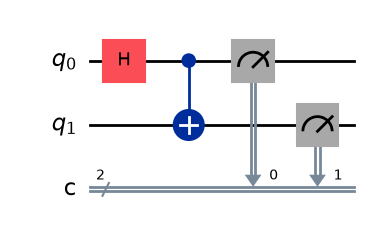

In [2]:
qc_orig = QuantumCircuit(2, 2)
qc_orig.h(0)
qc_orig.cx(0, 1)
qc_orig.measure([0, 1], [0, 1])
qc_orig.draw("mpl")

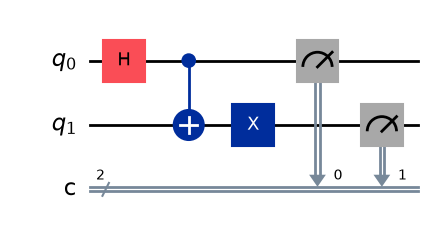

In [3]:
qc_mod = QuantumCircuit(2, 2)
qc_mod.h(0)
qc_mod.cx(0, 1)
qc_mod.x(1)   # the one added gate
qc_mod.measure([0, 1], [0, 1])
qc_mod.draw("mpl")

In [4]:
sim = AerSimulator()
counts_orig = sim.run(qc_orig, shots=100).result().get_counts()
counts_mod = sim.run(qc_mod, shots=100).result().get_counts()
print("Original:", counts_orig)
print("Modified:", counts_mod)

Original: {'11': 45, '00': 55}
Modified: {'10': 52, '01': 48}


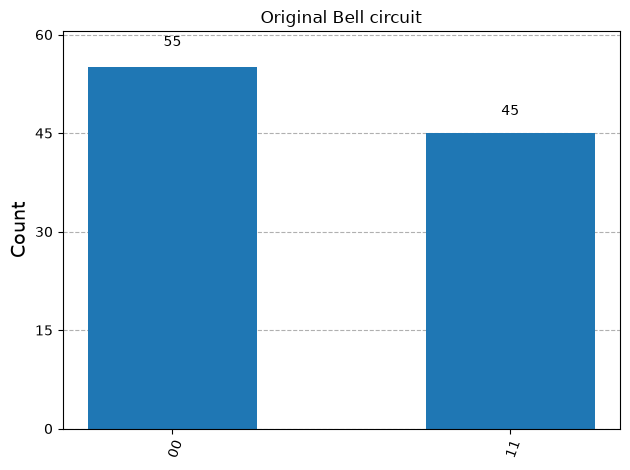

In [5]:
plot_histogram(counts_orig, title="Original Bell circuit")

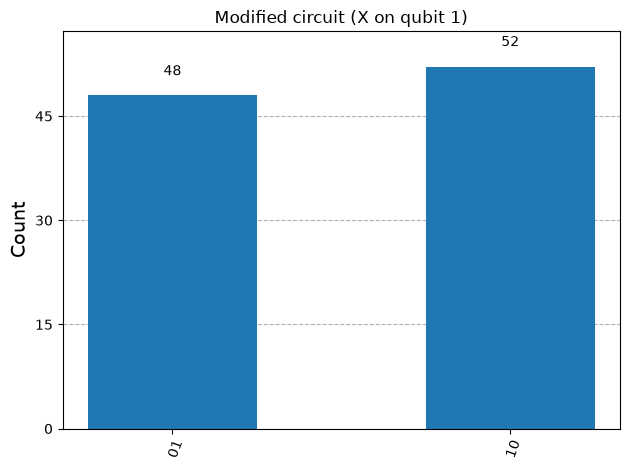

In [6]:
plot_histogram(counts_mod, title="Modified circuit (X on qubit 1)")

## Comparison and Explanation

- **Original (H, CNOT):** Predicted only `00` and `11`. Actual: `{'00': 55, '11': 45}`. Matches. The qubits always give the same result..
- **Modified (H, CNOT, X on qubit 1):** Predicted only `01` and `10`. Actual: `{'01': 48, '10': 52}`. Matches. The qubits always give opposite results.

**Why it changed:** The Bell state is (|00⟩ + |11⟩)/√2. The X gate flips qubit 1 only, turning |00⟩ into |01⟩ and |11⟩ into |10⟩. The state becomes (|01⟩ + |10⟩)/√2. The qubits are still entangled and each outcome is still about 50%, but the correlation changed from "same" to "opposite". Counts differ slightly from 50/50 because only 100 shots were used.